# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

--- First 5 Rows of the Dataset ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119390,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390,103050.000000,6797.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390,119390
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,926
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-10-21
freq,79330,NaN,NaN,NaN,13877,NaN,NaN,NaN,NaN,NaN,...,104641,NaN,NaN,NaN,89613,NaN,NaN,NaN,75166,1461
mean,NaN,0.370416,104.011416,2016.156554,NaN,27.165173,15.798241,0.927599,2.500302,1.856403,...,NaN,86.693382,189.266735,2.321149,NaN,101.831122,0.062518,0.571363,NaN,NaN
std,NaN,0.482918,106.863097,0.707476,NaN,13.605138,8.780829,0.998613,1.908286,0.579261,...,NaN,110.774548,131.655015,17.594721,NaN,50.535790,0.245291,0.792798,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,NaN,9.000000,62.000000,0.000000,NaN,69.290000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,...,NaN,14.000000,179.000000,0.000000,NaN,94.575000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,160.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,...,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. One thing that stood out to me was how much the booking times varied. Some customers booked only a few days in advance, while others booked as far as 737 days ahead. I also noticed that about 37% of bookings were canceled, which was higher than I expected. The dataset has 119,390 bookings and 32 columns, so there is a lot of information that could help identify different customer behaviors.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

Original dataset shape: (119390, 32)
Cleaned and scaled dataset shape: (70136, 4)

Features Selected: ['lead_time', 'stays_in_week_nights', 'adr', 'total_of_special_requests']


,lead_time,stays_in_week_nights,adr,total_of_special_requests
0,3.008576,-1.348127,-2.139896,-0.901417
1,-0.949159,-0.878440,-0.707673,-0.901417
2,-0.878274,-0.878440,-0.707673,-0.901417
3,-0.866460,-0.408753,-0.268457,0.268360
4,-1.031858,-0.408753,-0.096590,-0.901417


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead time, stays in week nights, average daily rate (ADR), and total special requests. I chose these because they help show how far in advance customers book, how long they stay, how much they spend, and what kind of services they request.

2. I expect to find different types of customers, like those who book far in advance, those who only stay a few nights, and those who spend more money or make more special requests. These patterns could help hotels better understand their customers and offer promotions that fit their needs.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

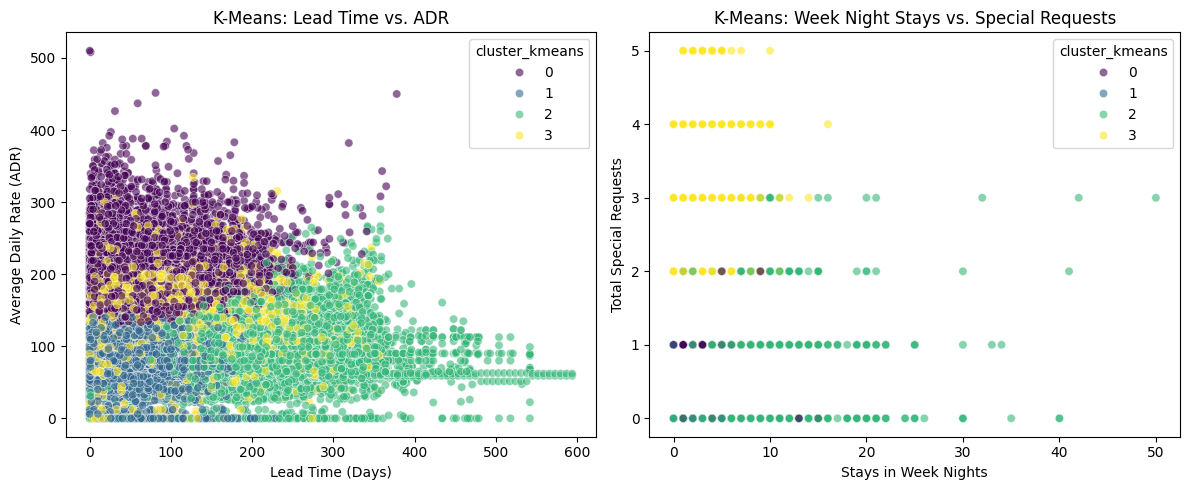


--- K-Means Cluster Summary Table (Averages) ---


,lead_time,stays_in_week_nights,adr,total_of_special_requests
cluster_kmeans,,,,
0,61.994711,2.742610,187.893593,0.593342
1,47.960712,2.165002,86.568804,0.414675
2,202.997009,4.739955,96.988372,0.554083
3,74.755739,2.535505,116.095600,2.249066


### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 4 because I wanted to separate customers into a few different groups based on their booking habits. Four clusters seemed like a good number to identify differences without making the results too complicated.

2. Cluster 0: These customers spend the most per night, averaging about $188, and book around 62 days in advance. They seem to be higher-spending guests.

Cluster 1: These customers have the lowest average daily rate at about $87 and stay around 2 nights during the week. They seem to be more budget-conscious or short-stay guests.

Cluster 2: These customers book the farthest in advance, around 203 days, and stay the longest at about 4.7 weeknights. They seem to be guests who plan longer trips ahead of time.

Cluster 3: These customers make the most special requests, averaging about 2.25 per booking. They seem to be guests who want more personalized services during their stay.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

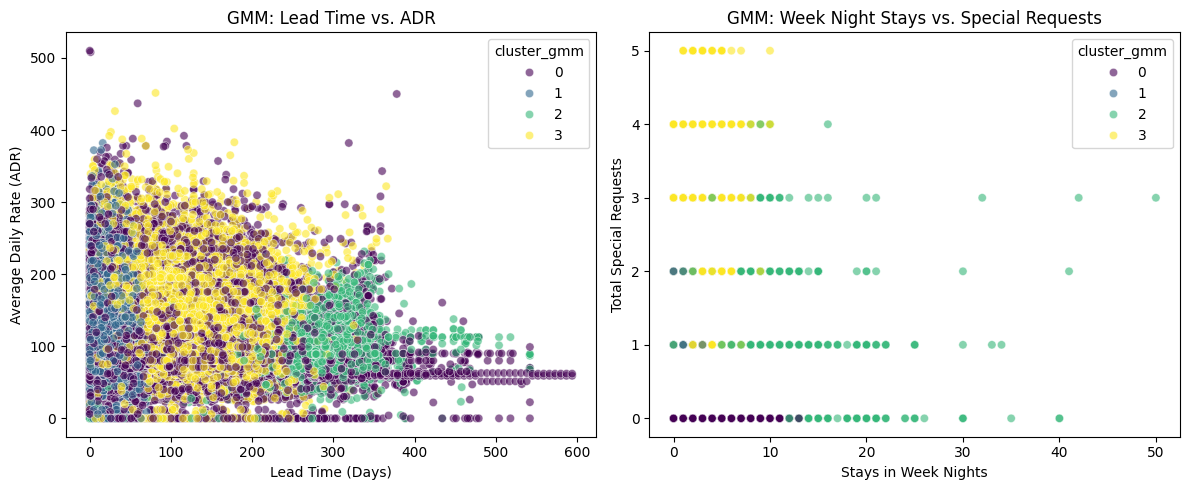


--- GMM Cluster Summary Table (Averages) ---


,lead_time,stays_in_week_nights,adr,total_of_special_requests
cluster_gmm,,,,
0,89.449160,2.851952,106.924612,0.000000
1,22.435135,2.088115,112.630646,1.195770
2,224.243355,6.124862,96.698192,1.304540
3,114.037785,2.951372,123.610442,1.642626


### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The GMM results were similar to K-Means because both models identified different customer groups based on booking behavior. However, GMM separated the groups a little differently. For example, GMM identified a group that booked around 224 days in advance and stayed about 6 weeknights, compared to around 203 days and 4.7 nights in K-Means. GMM also identified a group with no special requests.



2.GMM could help hotels understand customers who fit into more than one group. For example, a customer might book far in advance but also spend a lot of money. Since GMM uses probabilities, hotels could better understand these overlapping behaviors and decide which promotions or services would work best for different guests.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

K-Means WCSS (Inertia): 153581.94
GMM Average Log-Likelihood: -2.4914

--- Clustering Model Evaluation Metrics (10k Sample) ---
K-Means Silhouette Score: 0.2546 (Higher is better)
GMM Silhouette Score:     0.1293 (Higher is better)
K-Means Davies-Bouldin:   1.2554 (Lower is better)
GMM Davies-Bouldin:       1.8986 (Lower is better)


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed better based on the evaluation metrics. It had a higher Silhouette Score of 0.2546 compared to GMM's 0.1293. K-Means also had a lower Davies-Bouldin Index of 1.2554 compared to GMM's 1.8986. This shows that K-Means created more clearly separated clusters for this dataset.

5.3.I would recommend K-Means for a business analyst because it performed better on both metrics and is easier to understand and explain. It creates clear customer groups that hotels can use for marketing and promotions. GMM is still useful for customers with overlapping behaviors, but K-Means seems like the better choice for this dataset.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

--- Sorted K-Means Cluster Profiles (Sorted by ADR Descending) ---


,lead_time,stays_in_week_nights,adr,total_of_special_requests
cluster_kmeans,,,,
0,61.994711,2.742610,187.893593,0.593342
3,74.755739,2.535505,116.095600,2.249066
2,202.997009,4.739955,96.988372,0.554083
1,47.960712,2.165002,86.568804,0.414675



--- Real-world Business Segmentation Interpretation ---

Cluster 0:
  - Avg Lead Time: 62.0 days
  - Avg Week Night Stay: 2.7 nights
  - Avg Price per Night (ADR): $187.89
  - Avg Special Requests: 0.6

Cluster 3:
  - Avg Lead Time: 74.8 days
  - Avg Week Night Stay: 2.5 nights
  - Avg Price per Night (ADR): $116.10
  - Avg Special Requests: 2.2

Cluster 2:
  - Avg Lead Time: 203.0 days
  - Avg Week Night Stay: 4.7 nights
  - Avg Price per Night (ADR): $96.99
  - Avg Special Requests: 0.6

Cluster 1:
  - Avg Lead Time: 48.0 days
  - Avg Week Night Stay: 2.2 nights
  - Avg Price per Night (ADR): $86.57
  - Avg Special Requests: 0.4


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1.  The clusters represent different types of guests based on their booking habits. Cluster 0 includes higher-spending customers who pay about $188 per night. Cluster 1 represents more budget-conscious guests who stay for shorter periods. Cluster 2 includes customers who book far in advance and stay longer, while Cluster 3 represents guests who make the most special requests and may want more personalized experiences.



2.The hotel could offer premium packages or upgrades to Cluster 0 since they already spend more per night. Cluster 1 could receive discounts or affordable short-stay deals. Cluster 2 could be targeted with early booking discounts or extended-stay packages. For Cluster 3, the hotel could focus on personalized services and making sure their special requests are met. This would help the hotel better meet each group's needs and improve customer satisfaction.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hotel could offer premium packages or upgrades to Cluster 0 since they already spend more per night. Cluster 1 could receive discounts or affordable short-stay deals. Cluster 2 could be targeted with early booking discounts or extended-stay packages. For Cluster 3, the hotel could focus on personalized services and making sure their special requests are met. This would help the hotel better meet each group's needs and improve customer satisfaction.

2. I would use clustering when I want to find patterns or groups in data without already knowing the categories. For example, a hotel could use clustering to identify different types of customers. Supervised learning would be better for predicting a specific outcome, like whether a customer will cancel their booking.

3.  I would explain clustering as a way to group customers based on similar habits. This helps businesses better understand their customers and make smarter decisions about marketing, pricing, and customer service instead of treating everyone the same.

4. This assignment relates to my customized learning outcome because it helped me practice using data analytics to solve real business problems. As a finance student, I think understanding how to analyze data and identify patterns is important for making informed business decisions. It also showed me how machine learning can turn large amounts of data into useful information.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"